# 01. Dataset Exploration and Call Length Analytics

This notebook explores the Philippine Eagle audio recordings and their annotation selection tables:
1. Verifies pairing between audio files in `data/raw/audios/` and tables in `data/raw/selectionTables/`.
2. Inspects audio properties (duration, sample rate, channels).
3. Cleans annotations by filtering out rows marked as `Unnecessary`.
4. Computes analytics for Philippine Eagle call durations (average, min, max, percentiles).
5. Generates visualizations of call lengths, subtypes, and recording properties.

## 1. Imports and Configuration

In [1]:
import os
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf

warnings.filterwarnings("ignore")

# Random seed
SEED = 42
np.random.seed(SEED)

NOTEBOOK_ID = "01-dataset-exploration"

# Paths
CURRENT_PATH = Path.cwd()
PROJECT_ROOT = CURRENT_PATH if (CURRENT_PATH / "data").exists() else CURRENT_PATH.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
AUDIO_DIR = RAW_DIR / "audios"
TABLES_DIR = RAW_DIR / "selectionTables"

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Plotting style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.dpi"] = 150

print(f"Project root:     {PROJECT_ROOT}")
print(f"Audio directory:  {AUDIO_DIR}")
print(f"Tables directory: {TABLES_DIR}")
print(f"Figures output:   {FIGURES_DIR}")

Project root:     /home/fumei/Documents/MachineLearning/EagleSoundClassification
Audio directory:  /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/audios
Tables directory: /home/fumei/Documents/MachineLearning/EagleSoundClassification/data/raw/selectionTables
Figures output:   /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures


## 2. Audio and Selection Table Pairing Verification

In [2]:
# Scan raw audio files and selection tables
audio_files = sorted(AUDIO_DIR.glob("*.wav"))
table_files = sorted(TABLES_DIR.glob("*.txt"))

audio_stems = {f.stem: f for f in audio_files}
table_stems = {f.stem: f for f in table_files}

# Check matching between stems
paired_stems = sorted(list(set(audio_stems.keys()) & set(table_stems.keys())))
audios_without_table = sorted(list(set(audio_stems.keys()) - set(table_stems.keys())))
tables_without_audio = sorted(list(set(table_stems.keys()) - set(audio_stems.keys())))

print("=" * 60)
print("DATASET INVENTORY & PAIRING")
print("=" * 60)
print(f"Total audio files (.wav):            {len(audio_files)}")
print(f"Total selection tables (.txt):       {len(table_files)}")
print(f"Direct matches:                      {len(paired_stems)}")
print(f"Audios missing selection tables:     {len(audios_without_table)}")
for stem in audios_without_table:
    print(f"  - {stem}.wav")
print(f"Selection tables missing audio:      {len(tables_without_audio)}")
for stem in tables_without_audio:
    print(f"  - {stem}.txt")

# Check known duplicates or naming differences
if "converted_135598" in audios_without_table and "converted_converted_135598" in paired_stems:
    print("\nNote: converted_135598.wav is an exact byte duplicate of converted_converted_135598.wav, which pairs with converted_converted_135598.txt.")
print("=" * 60)

# Build pairing summary table
pairing_data = []
for f in audio_files:
    stem = f.stem
    has_table = stem in table_stems
    table_name = table_stems[stem].name if has_table else "None"
    status = "Paired" if has_table else ("Duplicate of converted_converted_135598" if stem == "converted_135598" else "Missing Table")
    pairing_data.append({
        "AudioFile": f.name,
        "AudioStem": stem,
        "HasSelectionTable": has_table,
        "SelectionTableFile": table_name,
        "Status": status
    })

df_pairing = pd.DataFrame(pairing_data)
df_pairing["Status"].value_counts().to_frame()

DATASET INVENTORY & PAIRING
Total audio files (.wav):            59
Total selection tables (.txt):       59
Direct matches:                      59
Audios missing selection tables:     0
Selection tables missing audio:      0


,count
Status,
Paired,59


## 3. Visualize Audio Pairing Status

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures/01-dataset-exploration-file-pairing-coverage.png


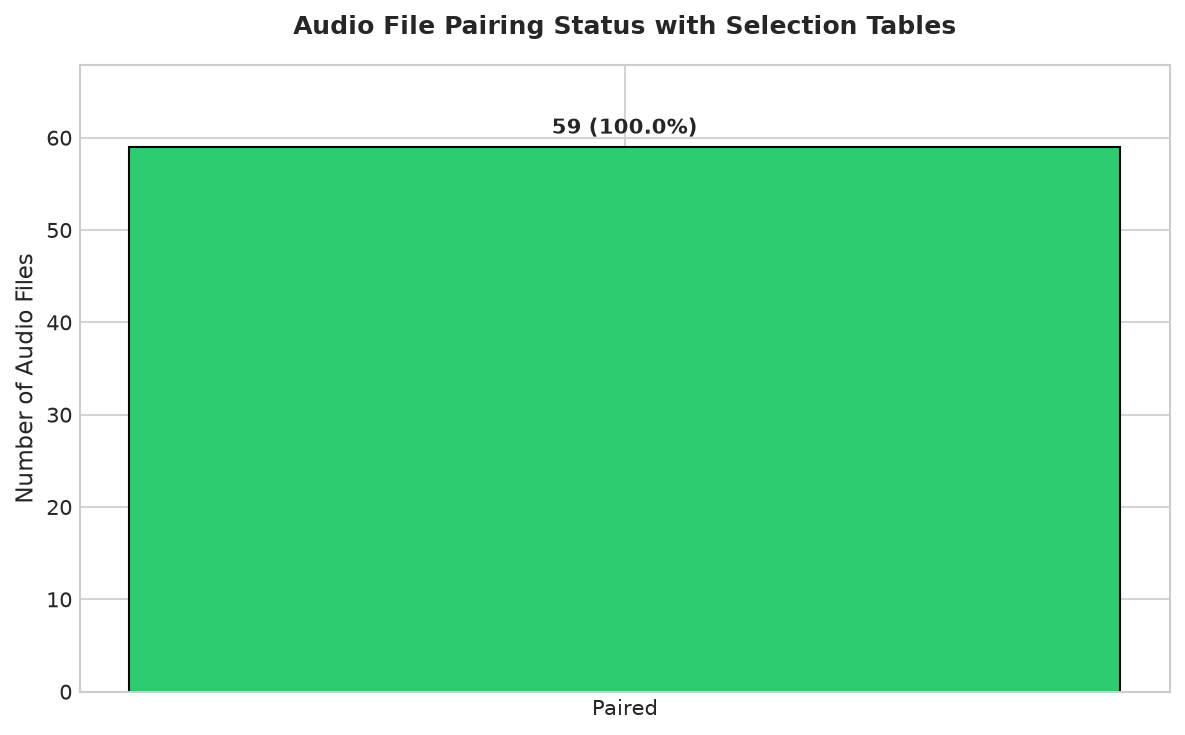

In [3]:
# Plot audio pairing status
status_counts = df_pairing["Status"].value_counts()
colors = ["#2ecc71", "#e74c3c", "#f39c12"]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(status_counts.index, status_counts.values, color=colors[:len(status_counts)], width=0.5, edgecolor="black")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f"{height} ({height/len(df_pairing)*100:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontweight="bold")

ax.set_title("Audio File Pairing Status with Selection Tables", pad=15, fontweight="bold")
ax.set_ylabel("Number of Audio Files")
ax.set_ylim(0, max(status_counts.values) * 1.15)
plt.tight_layout()

# Save figure
output_path = FIGURES_DIR / f"{NOTEBOOK_ID}-file-pairing-coverage.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {output_path}")
plt.show()

## 4. Inspect Audio Recording Properties and Durations

In [4]:
# Read audio file metadata
audio_meta = []
for f in audio_files:
    info = sf.info(f)
    audio_meta.append({
        "AudioFile": f.name,
        "AudioStem": f.stem,
        "Duration_s": info.duration,
        "Duration_min": info.duration / 60.0,
        "SampleRate_Hz": info.samplerate,
        "Channels": info.channels,
        "Format": info.format,
        "Subtype": info.subtype
    })

df_audio_props = pd.DataFrame(audio_meta)
total_audio_sec = df_audio_props["Duration_s"].sum()
total_audio_hrs = total_audio_sec / 3600.0

print("=" * 60)
print("AUDIO RECORDINGS SUMMARY")
print("=" * 60)
print(f"Total audio files:         {len(df_audio_props)}")
print(f"Total duration:            {total_audio_sec:.2f} seconds ({total_audio_hrs:.2f} hours)")
print(f"Mean duration:             {df_audio_props['Duration_s'].mean():.2f} seconds ({df_audio_props['Duration_s'].mean()/60:.2f} min)")
print(f"Min duration:              {df_audio_props['Duration_s'].min():.2f} seconds ({df_audio_props['Duration_s'].min()/60:.2f} min)")
print(f"Max duration:              {df_audio_props['Duration_s'].max():.2f} seconds ({df_audio_props['Duration_s'].max()/60:.2f} min)")
print(f"Median duration:           {df_audio_props['Duration_s'].median():.2f} seconds ({df_audio_props['Duration_s'].median()/60:.2f} min)")
print(f"Sample rates:              {df_audio_props['SampleRate_Hz'].unique().tolist()} Hz")
print(f"Channel counts:            {df_audio_props['Channels'].unique().tolist()} channel(s)")
print("=" * 60)

df_audio_props[["Duration_s", "Duration_min"]].describe()

AUDIO RECORDINGS SUMMARY
Total audio files:         59
Total duration:            14605.97 seconds (4.06 hours)
Mean duration:             247.56 seconds (4.13 min)
Min duration:              4.94 seconds (0.08 min)
Max duration:              2528.68 seconds (42.14 min)
Median duration:           132.57 seconds (2.21 min)
Sample rates:              [44100] Hz
Channel counts:            [1] channel(s)


,Duration_s,Duration_min
count,59.000000,59.000000
mean,247.558768,4.125979
std,397.189651,6.619828
min,4.937143,0.082286
25%,37.991179,0.633186
50%,132.572880,2.209548
75%,321.977902,5.366298
max,2528.683379,42.144723


## 5. Load and Consolidate Selection Tables

In [5]:
# Load all selection tables into a single DataFrame
table_dfs = []
for f in table_files:
    df_item = pd.read_csv(f, sep="\t")
    df_item.columns = [col.strip() for col in df_item.columns]
    df_item["TableFile"] = f.name
    df_item["AudioStem"] = f.stem
    table_dfs.append(df_item)

df_all_annotations = pd.concat(table_dfs, ignore_index=True)
df_all_annotations["Duration (s)"] = df_all_annotations["End Time (s)"] - df_all_annotations["Begin Time (s)"]

print(f"Loaded {len(table_files)} selection tables.")
print(f"Total annotations: {len(df_all_annotations)}")
df_all_annotations.head(5)

Loaded 59 selection tables.
Total annotations: 4066


,Selection,View,Channel,Begin Time (s),End Time (s),Low Freq (Hz),High Freq (Hz),Peak Freq (Hz),BW 90% (Hz),Type,Quality,TableFile,AudioStem,Duration (s)
0,1,Spectrogram 1,1,0.000000,4.226919,0.000,18850.315,172.266,861.328,Unnecessary,NaN,converted_135598.txt,converted_135598,4.226919
1,2,Spectrogram 1,1,6.209091,7.028494,2065.574,2995.082,2239.453,689.062,PhilEagle_long,Low,converted_135598.txt,converted_135598,0.819403
2,3,Spectrogram 1,1,8.027765,8.832179,2117.213,2685.246,2411.719,344.531,PhilEagle_long,Medium,converted_135598.txt,converted_135598,0.804414
3,4,Spectrogram 1,1,11.578794,12.198342,2168.852,2685.246,2670.117,258.398,PhilEagle_long,Low,converted_135598.txt,converted_135598,0.619548
4,5,Spectrogram 1,1,13.387476,13.977046,2117.213,2685.246,2411.719,430.664,PhilEagle_long,Low,converted_135598.txt,converted_135598,0.589570


## 6. Filter Out Unnecessary Annotations

In [6]:
# View raw annotation types
raw_type_counts = df_all_annotations["Type"].value_counts(dropna=False)
print("Raw annotation types:")
print(raw_type_counts)

# Filter out all variations of unnecessary (including typos like Unnecessaryq, Unecessary, Unnecessasry)
unnecessary_regex = r"un+ec+es+"
unnecessary_mask = df_all_annotations["Type"].str.contains(unnecessary_regex, case=False, na=False)

disregarded_count = unnecessary_mask.sum()
disregarded_types = df_all_annotations.loc[unnecessary_mask, "Type"].value_counts().to_dict()

print("\n" + "=" * 60)
print(f"Disregarded {disregarded_count} unnecessary rows:")
for t, cnt in disregarded_types.items():
    print(f"  - '{t}': {cnt}")
print("=" * 60)

# Keep only relevant call rows
df_filtered = df_all_annotations[~unnecessary_mask].copy()

# Fix minor typo (PhilEagle_longt -> PhilEagle_long)
df_filtered["CleanType"] = df_filtered["Type"].replace({"PhilEagle_longt": "PhilEagle_long"})

# Create eagle call and ambiguous flags
df_filtered["IsEagleCall"] = df_filtered["CleanType"].str.startswith("PhilEagle", na=False)
df_filtered["IsAmbiguous"] = df_filtered["CleanType"] == "Ambiguous"

print("\nFiltered annotation distribution:")
print(df_filtered["CleanType"].value_counts())
print(f"\nTotal Confirmed Eagle Calls: {df_filtered['IsEagleCall'].sum()}")
print(f"Total Ambiguous Calls:         {df_filtered['IsAmbiguous'].sum()}")

Raw annotation types:
Type
PhilEagle_short    2744
PhilEagle_long     1079
Unnecessary         148
Ambiguous            87
Unnecessaryq          2
Unecessary            2
Unnecessasry          2
PhilEagle_longt       2
Name: count, dtype: int64

Disregarded 154 unnecessary rows:
  - 'Unnecessary': 148
  - 'Unnecessaryq': 2
  - 'Unecessary': 2
  - 'Unnecessasry': 2

Filtered annotation distribution:
CleanType
PhilEagle_short    2744
PhilEagle_long     1081
Ambiguous            87
Name: count, dtype: int64

Total Confirmed Eagle Calls: 3825
Total Ambiguous Calls:         87


## 7. Calculate Eagle Call Length Analytics

In [7]:
# Analyze duration of confirmed eagle calls
df_eagle = df_filtered[df_filtered["IsEagleCall"]].copy()

def compute_stats(series: pd.Series) -> dict:
    return {
        "Count": int(len(series)),
        "Mean (s)": float(series.mean()),
        "Std Dev (s)": float(series.std()),
        "Min (s)": float(series.min()),
        "25% (Q1) (s)": float(series.quantile(0.25)),
        "Median (s)": float(series.median()),
        "75% (Q3) (s)": float(series.quantile(0.75)),
        "95% (s)": float(series.quantile(0.95)),
        "Max (s)": float(series.max()),
        "IQR (s)": float(series.quantile(0.75) - series.quantile(0.25))
    }

stats_dict = {
    "All Eagle Calls": compute_stats(df_eagle["Duration (s)"])
}

for call_type in sorted(df_eagle["CleanType"].unique()):
    subset = df_eagle[df_eagle["CleanType"] == call_type]["Duration (s)"]
    stats_dict[call_type] = compute_stats(subset)

df_ambiguous = df_filtered[df_filtered["IsAmbiguous"]]
if len(df_ambiguous) > 0:
    stats_dict["Ambiguous"] = compute_stats(df_ambiguous["Duration (s)"])

df_analytics = pd.DataFrame(stats_dict).T

print("=" * 80)
print("EAGLE CALL DURATION ANALYTICS (IN SECONDS)")
print("=" * 80)
print(df_analytics.round(4).to_string())
print("=" * 80)

mean_len = df_eagle["Duration (s)"].mean()
min_len = df_eagle["Duration (s)"].min()
max_len = df_eagle["Duration (s)"].max()
median_len = df_eagle["Duration (s)"].median()

print(f"\nKey Duration Statistics:")
print(f"  * Average (Mean): {mean_len:.4f} seconds ({mean_len*1000:.1f} ms)")
print(f"  * Minimum:        {min_len:.4f} seconds ({min_len*1000:.1f} ms)")
print(f"  * Maximum:        {max_len:.4f} seconds ({max_len*1000:.1f} ms)")
print(f"  * Median:         {median_len:.4f} seconds ({median_len*1000:.1f} ms)")

EAGLE CALL DURATION ANALYTICS (IN SECONDS)
                  Count  Mean (s)  Std Dev (s)  Min (s)  25% (Q1) (s)  Median (s)  75% (Q3) (s)  95% (s)  Max (s)  IQR (s)
All Eagle Calls  3825.0    0.7346       0.2872   0.1250        0.5447      0.7043        0.9001   1.2538   2.2634   0.3554
PhilEagle_long   1081.0    0.8696       0.2945   0.2273        0.6530      0.7894        1.0392   1.4555   2.2634   0.3863
PhilEagle_short  2744.0    0.6814       0.2661   0.1250        0.4929      0.6629        0.8447   1.1686   1.5415   0.3518
Ambiguous          87.0    0.8331       0.3973   0.1849        0.5146      0.7944        1.0417   1.5208   2.0185   0.5271

Key Duration Statistics:
  * Average (Mean): 0.7346 seconds (734.6 ms)
  * Minimum:        0.1250 seconds (125.0 ms)
  * Maximum:        2.2634 seconds (2263.4 ms)
  * Median:         0.7043 seconds (704.3 ms)


## 8. Visualize Eagle Call Duration Distribution

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures/01-dataset-exploration-eagle-call-duration-distribution.png


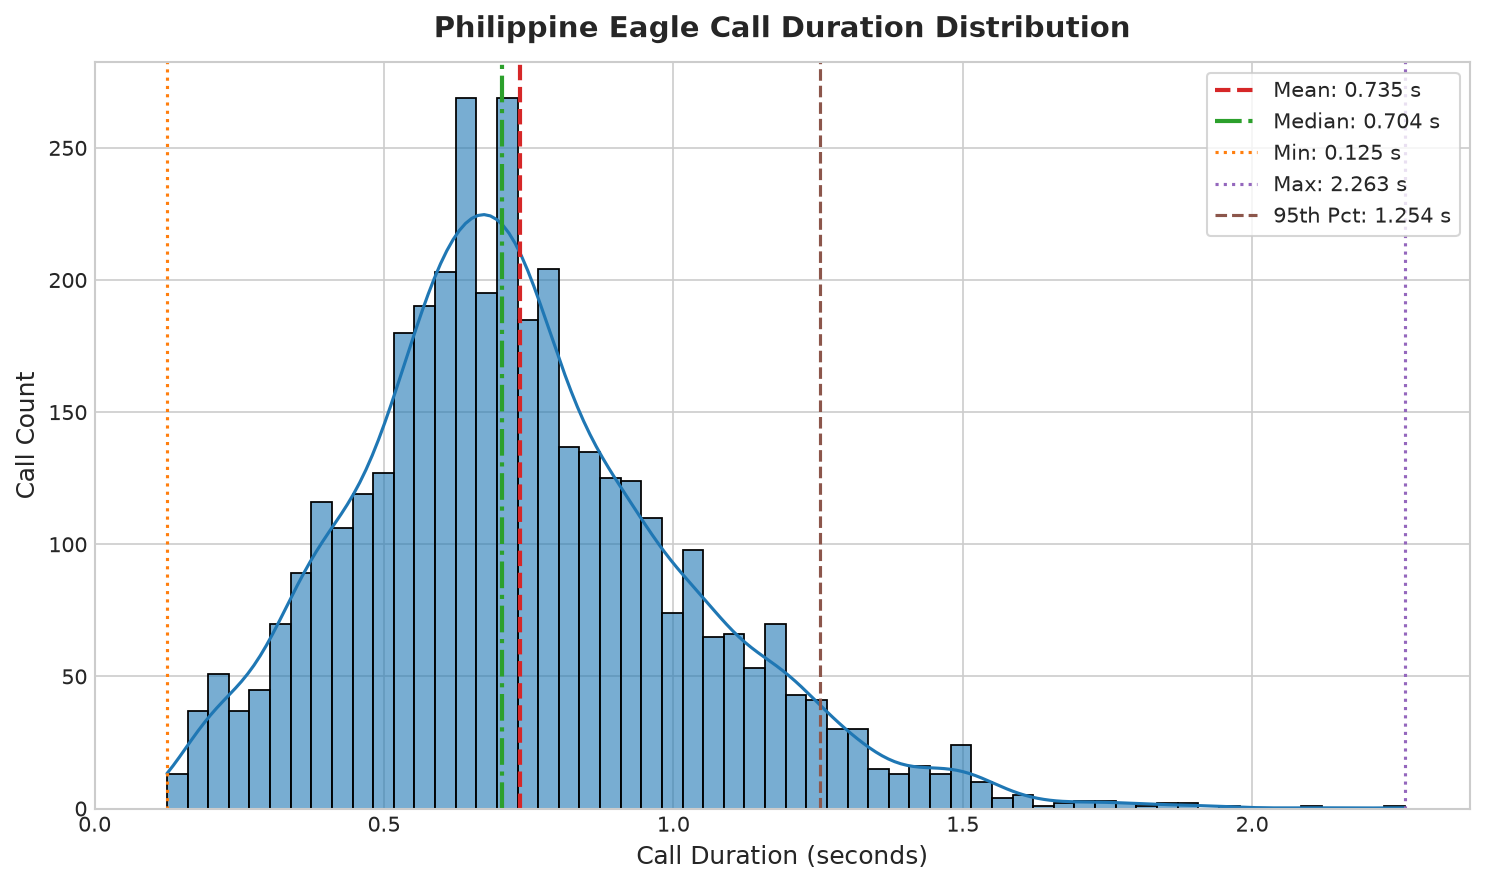

In [8]:
# Plot histogram and KDE of eagle call durations
durations = df_eagle["Duration (s)"]

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(durations, kde=True, bins=60, color="#1f77b4", edgecolor="black", alpha=0.6, ax=ax)

# Reference lines
ax.axvline(mean_len, color="#d62728", linestyle="--", linewidth=2, label=f"Mean: {mean_len:.3f} s")
ax.axvline(median_len, color="#2ca02c", linestyle="-.", linewidth=2, label=f"Median: {median_len:.3f} s")
ax.axvline(min_len, color="#ff7f0e", linestyle=":", linewidth=1.5, label=f"Min: {min_len:.3f} s")
ax.axvline(max_len, color="#9467bd", linestyle=":", linewidth=1.5, label=f"Max: {max_len:.3f} s")

p95 = durations.quantile(0.95)
ax.axvline(p95, color="#8c564b", linestyle="--", linewidth=1.5, label=f"95th Pct: {p95:.3f} s")

ax.set_title("Philippine Eagle Call Duration Distribution", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Call Duration (seconds)", fontsize=12)
ax.set_ylabel("Call Count", fontsize=12)
ax.legend(loc="upper right", frameon=True, fontsize=10)
ax.set_xlim(0, max_len * 1.05)

plt.tight_layout()

# Save figure
fig_path = FIGURES_DIR / f"{NOTEBOOK_ID}-eagle-call-duration-distribution.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()

## 9. Visualize Call Duration by Subtype and Quality

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures/01-dataset-exploration-call-duration-by-subtype.png


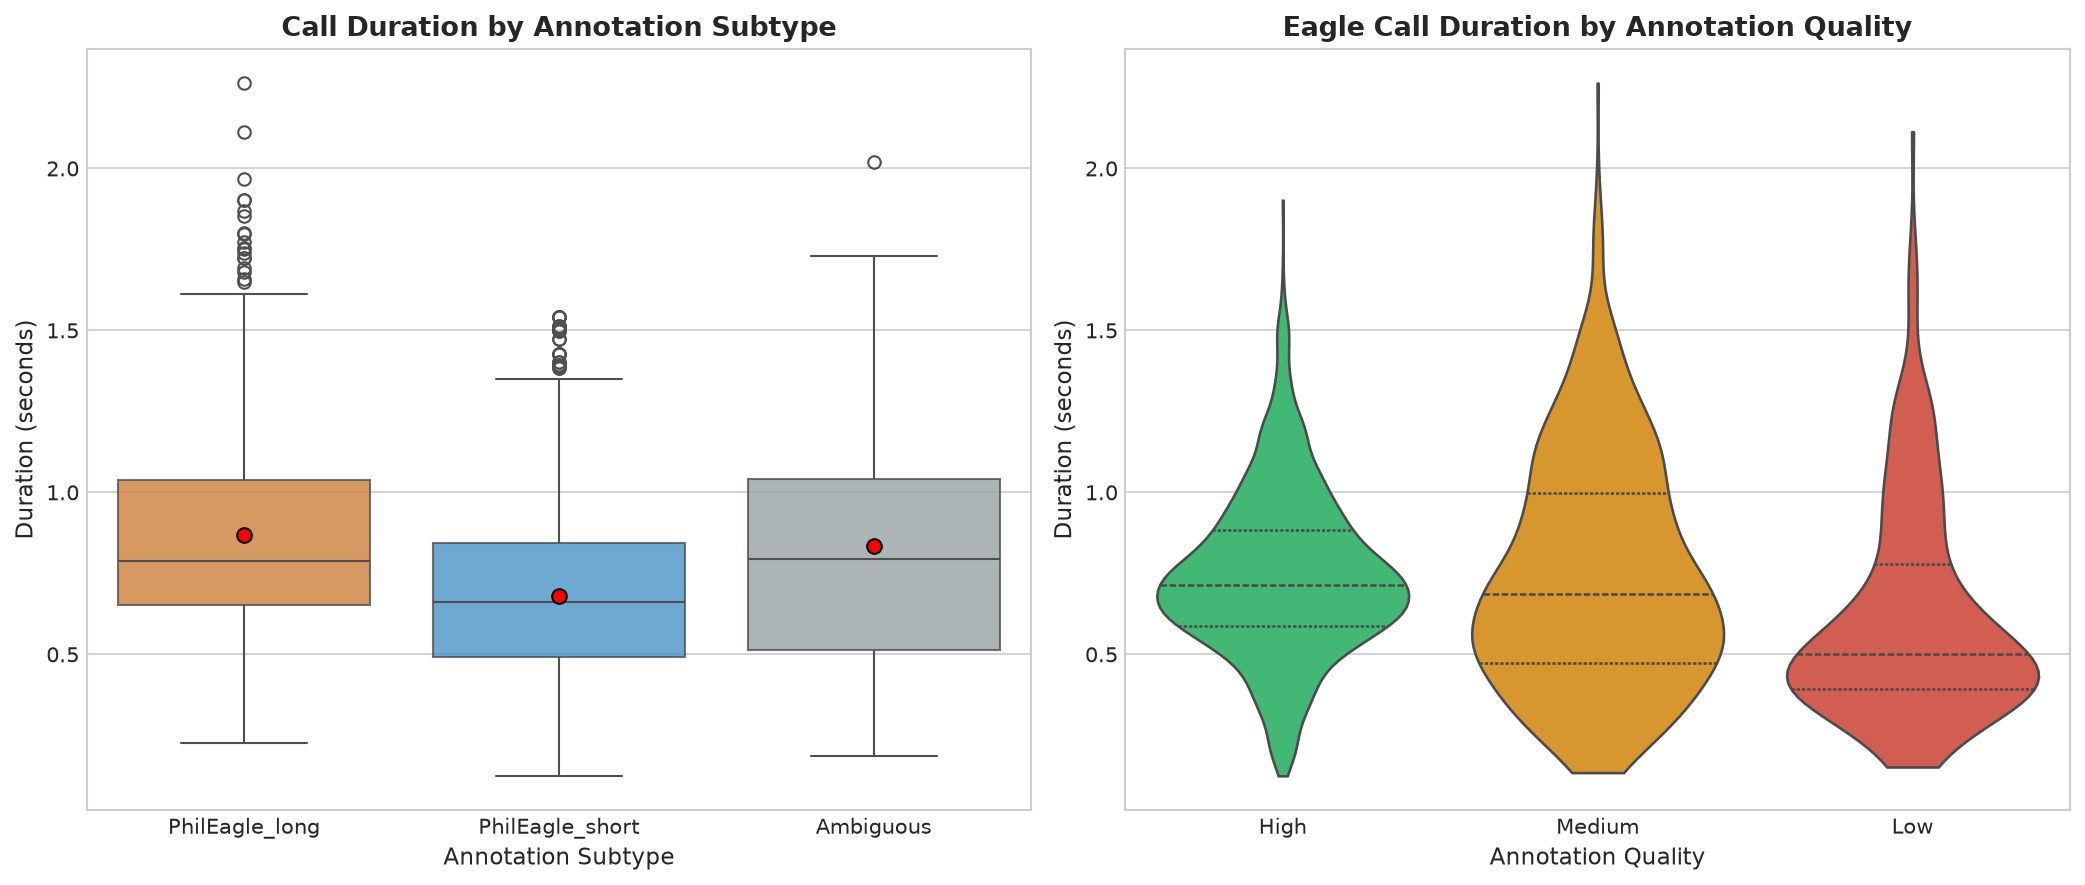

In [9]:
# Compare call duration across subtype and quality
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Panel 1: Duration by subtype
type_palette = {"PhilEagle_short": "#3498db", "PhilEagle_long": "#e67e22", "Ambiguous": "#95a5a6"}
sns.boxplot(
    data=df_filtered,
    x="CleanType",
    y="Duration (s)",
    palette=type_palette,
    ax=axes[0],
    boxprops=dict(alpha=0.8),
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": 7}
)
axes[0].set_title("Call Duration by Annotation Subtype", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Annotation Subtype", fontsize=11)
axes[0].set_ylabel("Duration (seconds)", fontsize=11)

# Panel 2: Duration by quality for eagle calls
quality_order = ["High", "Medium", "Low"]
valid_quality_df = df_eagle[df_eagle["Quality"].isin(quality_order)]
quality_palette = {"High": "#2ecc71", "Medium": "#f39c12", "Low": "#e74c3c"}

sns.violinplot(
    data=valid_quality_df,
    x="Quality",
    y="Duration (s)",
    order=quality_order,
    palette=quality_palette,
    ax=axes[1],
    inner="quartile",
    cut=0
)
axes[1].set_title("Eagle Call Duration by Annotation Quality", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Annotation Quality", fontsize=11)
axes[1].set_ylabel("Duration (seconds)", fontsize=11)

plt.tight_layout()

# Save figure
fig_path = FIGURES_DIR / f"{NOTEBOOK_ID}-call-duration-by-subtype.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()

## 10. Visualize Call Frequency and Quality Distribution

Saved figure: /home/fumei/Documents/MachineLearning/EagleSoundClassification/outputs/figures/01-dataset-exploration-call-counts-and-quality.png


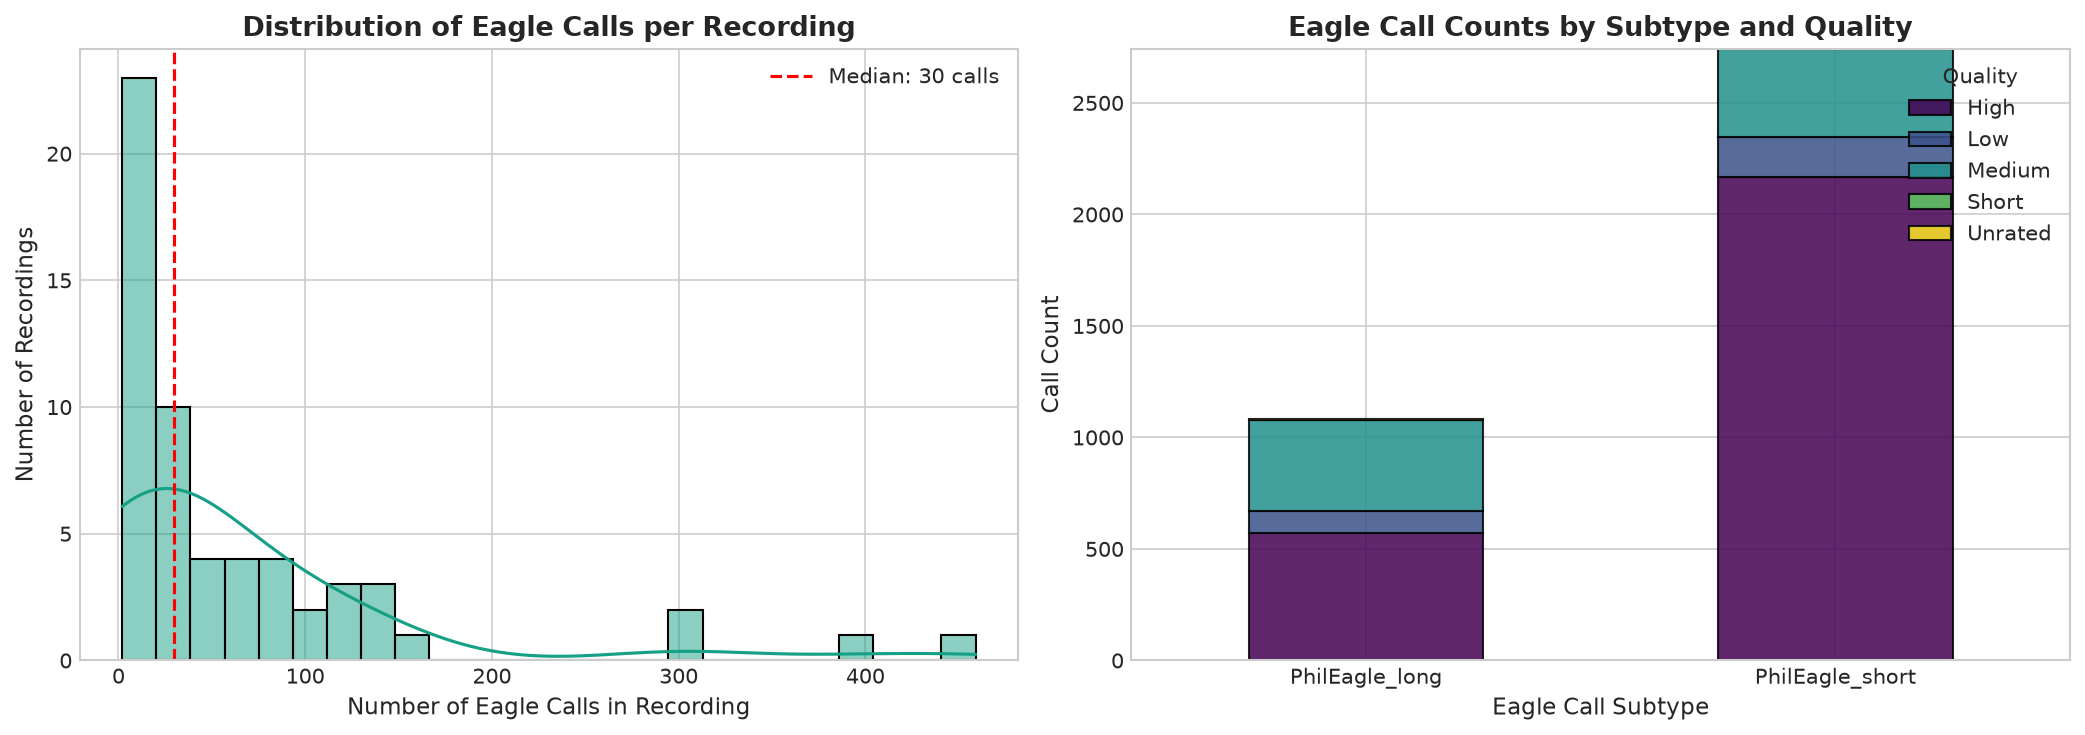

In [10]:
# Plot call frequency per audio file and quality breakdown
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Calls per audio file
calls_per_audio = df_eagle.groupby("AudioStem").size()
sns.histplot(calls_per_audio, bins=25, kde=True, color="#16a085", ax=axes[0], edgecolor="black")
axes[0].set_title("Distribution of Eagle Calls per Recording", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Number of Eagle Calls in Recording", fontsize=11)
axes[0].set_ylabel("Number of Recordings", fontsize=11)
axes[0].axvline(calls_per_audio.median(), color="red", linestyle="--", label=f"Median: {calls_per_audio.median():.0f} calls")
axes[0].legend()

# Panel 2: Eagle call counts by subtype and quality
count_cross = pd.crosstab(df_eagle["CleanType"], df_eagle["Quality"].fillna("Unrated"))
count_cross.plot(kind="bar", stacked=True, colormap="viridis", ax=axes[1], edgecolor="black", alpha=0.85)
axes[1].set_title("Eagle Call Counts by Subtype and Quality", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Eagle Call Subtype", fontsize=11)
axes[1].set_ylabel("Call Count", fontsize=11)
axes[1].legend(title="Quality", loc="upper right")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()

# Save figure
fig_path = FIGURES_DIR / f"{NOTEBOOK_ID}-call-counts-and-quality.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved figure: {fig_path}")
plt.show()

## 11. Summary of Findings

In [11]:
# Summary metrics dictionary
summary_findings = {
    "Total Audio Files": len(audio_files),
    "Total Audio Hours": round(total_audio_hrs, 2),
    "Total Selection Tables": len(table_files),
    "Audio-Table Matches": len(paired_stems),
    "Audios Missing Tables": len(audios_without_table),
    "Total Raw Annotations": len(df_all_annotations),
    "Disregarded Unnecessary Rows": int(disregarded_count),
    "Confirmed Eagle Calls": len(df_eagle),
    "  - PhilEagle_short Calls": int((df_eagle["CleanType"] == "PhilEagle_short").sum()),
    "  - PhilEagle_long Calls": int((df_eagle["CleanType"] == "PhilEagle_long").sum()),
    "Ambiguous Calls": len(df_ambiguous),
    "Eagle Call Mean Duration (s)": round(float(mean_len), 4),
    "Eagle Call Min Duration (s)": round(float(min_len), 4),
    "Eagle Call Max Duration (s)": round(float(max_len), 4),
    "Eagle Call Median Duration (s)": round(float(median_len), 4),
    "Eagle Call 95th Percentile Duration (s)": round(float(p95), 4)
}

print("=" * 60)
print("DATASET EXPLORATION SUMMARY")
print("=" * 60)
for k, v in summary_findings.items():
    print(f"{k:<40}: {v}")
print("=" * 60)

DATASET EXPLORATION SUMMARY
Total Audio Files                       : 59
Total Audio Hours                       : 4.06
Total Selection Tables                  : 59
Audio-Table Matches                     : 59
Audios Missing Tables                   : 0
Total Raw Annotations                   : 4066
Disregarded Unnecessary Rows            : 154
Confirmed Eagle Calls                   : 3825
  - PhilEagle_short Calls               : 2744
  - PhilEagle_long Calls                : 1081
Ambiguous Calls                         : 87
Eagle Call Mean Duration (s)            : 0.7346
Eagle Call Min Duration (s)             : 0.125
Eagle Call Max Duration (s)             : 2.2634
Eagle Call Median Duration (s)          : 0.7043
Eagle Call 95th Percentile Duration (s) : 1.2538
